In [1]:
#persistence bhaneko chai 
#each workflow ko STATE lai store garnu ho for future use


#Workflow bhaneko chai START node dekhi END node samma hune operation ko flow

#State bhaneko chai Structure Memory ho i.e Dictionary ho jasle chai Value store garcha

#Each Node le same State lai access garcha and if necessary value update garcha

In [5]:
#lets use RAM as memory to store value

#llm model

import os 
from dotenv import load_dotenv
load_dotenv()

MODEL_API_KEY = os.getenv("MODEL_API_KEY")
MODEL_NAME  = os.getenv("MODEL_NAME")
MODEL_PROVIDER = os.getenv("MODEL_PROVIDER")

#langchain import
from langchain.chat_models import init_chat_model
from langchain_core.prompts import ChatPromptTemplate


llm = init_chat_model(
  model=MODEL_NAME,
  model_provider=MODEL_PROVIDER,
  api_key = MODEL_API_KEY
)

#node1 that create Joke 
system_prompt_joke = """Create one short, funny, and clever one-sentence joke about topic given by User. Return only the joke."""

prompt_template_joke = ChatPromptTemplate.from_messages(
  [
    ("system",system_prompt_joke),
    ("human","{joke_topic}")
  ]
)


#node2 chai tyo joke lai explain garcha

system_prompt_explain="""Explain the joke in simple English in 1–2 short sentences. Return only the explanation."""

prompt_template_explain = ChatPromptTemplate.from_messages([
  ("system",system_prompt_explain),
  ("human","{joke}")
])


In [6]:
#State banaune
from typing import TypedDict


class GraphState(TypedDict):
  topic : str 
  joke : str 
  explanation : str 

In [13]:
#node1 jasle joke generate garcha

from langchain_core.output_parsers import StrOutputParser

# parser = StrOutputParser()


def joke_generator_node(state : GraphState):
  topic = state["topic"]
  
  chain_joke = prompt_template_joke | llm 
  
  joke = chain_joke.invoke({
    "joke_topic" : topic
  })
  
  return {
    "joke" : joke
  }
  
  
  
#node2 jasle Joke lai Explain garcha


def joke_explanator_node(state : GraphState):
  
  joke = state["joke"]
  
  chain_explanator = prompt_template_explain | llm 
  
  explanation = chain_explanator.invoke({
    "joke" : joke 
  })
  
  return {
    "explanation" : explanation
  }

In [14]:
#abo graph banaune
from langgraph.graph import START, END, StateGraph
from langgraph.checkpoint.memory import InMemorySaver


checkpointer = InMemorySaver()

builder = StateGraph(GraphState)

#node haru banaune
builder.add_node("joke_generator",joke_generator_node)
builder.add_node("joke_explanator",joke_explanator_node)


#node haru connect garne
builder.add_edge(START,"joke_generator")
builder.add_edge("joke_generator","joke_explanator")
builder.add_edge("joke_explanator",END)


#graph banaune
graph = builder.compile(checkpointer=checkpointer)

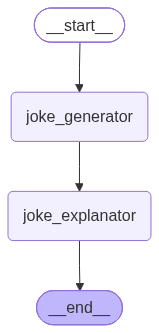

In [15]:
graph

In [19]:
thread_id = "user_1"
config1 = {
  "configurable" : {
    "thread_id" : thread_id
  }
}

while True:
  
  user_input = input("TOPIC (Type 'exit' to Exit): ")
  
  if user_input.strip().lower() == "exit":
    break
  
  print(f"USER : {user_input}")
  
  response = graph.invoke({
    "topic" : user_input
  },config=config1)
  
  print(f"AI : {response}")
  

USER : apple
AI : {'topic': 'apple', 'joke': AIMessage(content='I bought an apple so smart, it was an i-apple.', additional_kwargs={'reasoning_content': 'We need to produce a short, funny, clever one-sentence joke about "apple". Only joke. Let\'s think: maybe pun on apple fruit, or apple the company. Short. Something like "I tried to make a fruit salad with apples, but it kept iOS-ing the other fruits." Or "My apple fell from the tree and said \'I’m a Mac-apple\'." Maybe a pun: "Why did the apple go to the doctor? Because it felt a-peel." That\'s a classic. But need clever, short. Maybe: "I ate an apple and realized it was a fruit that was too Apple-icious." Eh. Or "I told my apple it was too \'core-ny\'." Hmm. Let\'s do: "Why don\'t apples ever get lost? Because they always find their core." But we want one sentence. Something like: "I bought an apple that was so smart, it was a \'Mac\'." But pun. Or "Why did the apple join the gym? To get a \'core\' workout." Might be too long. Let\'

In [20]:
thread_id = "user_2"
config2 = {
  "configurable" : {
    "thread_id" : thread_id
  }
}

while True:
  
  user_input = input("TOPIC (Type 'exit' to Exit): ")
  
  if user_input.strip().lower() == "exit":
    break
  
  print(f"USER : {user_input}")
  
  response = graph.invoke({
    "topic" : user_input
  },config=config2)
  
  print(f"AI : {response}")
  

USER : cat
AI : {'topic': 'cat', 'joke': AIMessage(content='Cats are the only animals that can stare at you for hours and still make you feel like the boss—until they knock over your coffee.', additional_kwargs={'reasoning_content': 'The user: "cat". We need a short, funny, clever one-sentence joke about cats. Return only the joke. No extra. Let\'s produce something witty. Maybe: "I told my cat he was a great musician; he just kept me on the \'purr-fect\' rhythm." Or "My cat\'s favorite type of music is \'purr\'-cussion." Something about cat. Let\'s do: "Cats are just like Wi-Fi; they always find the strongest signal, but you never know where they\'ll be." That\'s maybe a bit long. Let\'s keep it short. "Cats don\'t chase mice; they chase their own tail\'s ego." Eh. Let\'s pick: "My cat\'s idea of a workout is chasing the red dot, which is basically cardio for fur." That\'s okay. But maybe: "Cats are like software updates: they appear when you least expect them and have you wondering w

In [26]:
state = graph.get_state(
  config=config1
)

state.config

{'configurable': {'thread_id': 'user_1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1cb8d0-b76c-6e72-8016-ba27f4bb15aa'}}

In [27]:
history = graph.get_state_history(
  config=config1
)

# for state in history:
#   print(state.values)
#   print(state.config)